<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/Bai123.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI TẬP: PHÂN TÍCH VÀ XÂY DỰNG MÔ HÌNH HỒI QUY – DIABETES

**Mục tiêu:** hoàn thành đủ 3 bài trong đề: (1) EDA với 3 feature; (2) so sánh các nhóm feature; (3) so sánh các thuật toán hồi quy.

**Cách chạy trên Google Colab:** mở file notebook này bằng Colab, chọn **Runtime (Thời gian chạy) → Run all (Chạy tất cả)**. Notebook dùng dữ liệu Diabetes tích hợp trong `scikit-learn`, không cần tải CSV hay sửa đường dẫn.

> `target` là chỉ số định lượng về mức độ tiến triển bệnh sau một năm trong bộ dữ liệu mẫu; không dùng notebook này để chẩn đoán y khoa.

## 0. Import thư viện và nạp dữ liệu

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Dữ liệu Diabetes được tích hợp trong scikit-learn nên không cần tải file bên ngoài.
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()
df = X.copy()
df["target"] = y

print(f"Số mẫu: {df.shape[0]}")
print(f"Số feature đầu vào: {X.shape[1]}")
print("Các feature:", list(X.columns))
display(df.head())

Số mẫu: 442
Số feature đầu vào: 10
Các feature: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


# BÀI 1. CHỌN 3 FEATURE VÀ PHÂN TÍCH DỮ LIỆU

Chọn `bmi`, `s5`, `bp` để khảo sát. Đây là ba feature có tương quan Pearson tuyệt đối tương đối cao với `target` trong bộ dữ liệu Diabetes. Ta sẽ xem phân phối, ngoại lệ theo IQR, tương quan với target và scatter plot.

## 1.1. Kiểm tra nhanh chất lượng dữ liệu

In [ ]:
print("Kích thước dữ liệu:", df.shape)
print("\nSố giá trị thiếu theo cột:")
display(df.isna().sum().to_frame("missing_values"))
print("Số dòng trùng lặp:", int(df.duplicated().sum()))

Kích thước dữ liệu: (442, 11)

Số giá trị thiếu theo cột:


,missing_values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Số dòng trùng lặp: 0


## 1.2. Phân phối của 3 feature

bmi: trung bình = -0.0000, trung vị = -0.0073, độ lệch (skew) = 0.5981


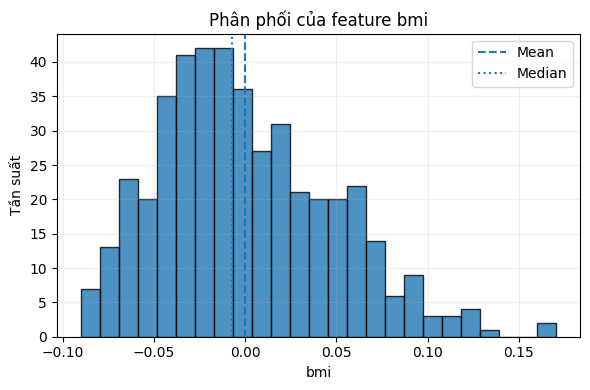

s5: trung bình = 0.0000, trung vị = -0.0019, độ lệch (skew) = 0.2918


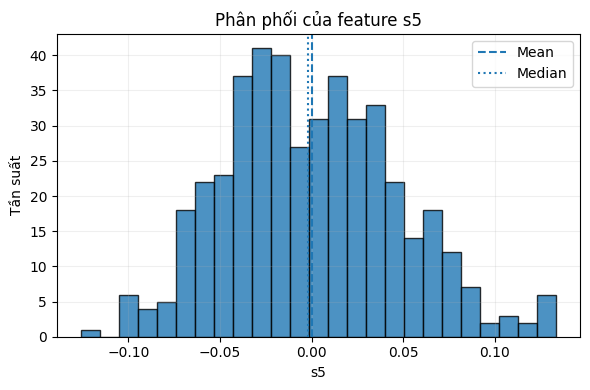

bp: trung bình = -0.0000, trung vị = -0.0057, độ lệch (skew) = 0.2907


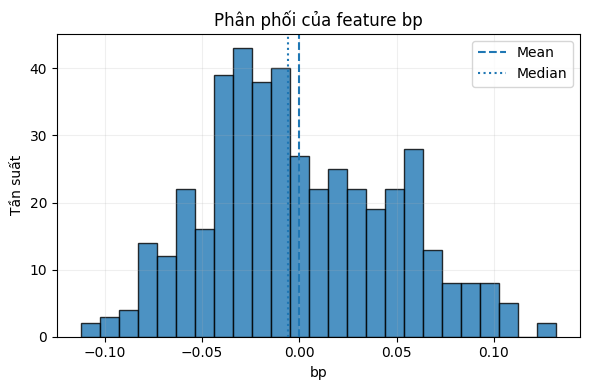

In [ ]:
features_3 = ["bmi", "s5", "bp"]

for col in features_3:
    values = df[col]
    print(f"{col}: trung bình = {values.mean():.4f}, trung vị = {values.median():.4f}, độ lệch (skew) = {values.skew():.4f}")
    plt.figure(figsize=(6, 4))
    plt.hist(values, bins=25, edgecolor="black", alpha=0.8)
    plt.axvline(values.mean(), linestyle="--", label="Mean")
    plt.axvline(values.median(), linestyle=":", label="Median")
    plt.title(f"Phân phối của feature {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### Nhận xét phân phối tự động

In [ ]:
for col in features_3:
    skew = df[col].skew()
    if skew > 0.5:
        desc = "lệch phải tương đối rõ"
    elif skew < -0.5:
        desc = "lệch trái tương đối rõ"
    else:
        desc = "khá cân đối hoặc chỉ lệch nhẹ"
    print(f"- {col}: phân phối {desc} (skew = {skew:.3f}).")
print("Lưu ý: các feature của bộ dữ liệu đã được chuẩn hóa; vì vậy giá trị có thể âm hoặc dương quanh 0.")

- bmi: phân phối lệch phải tương đối rõ (skew = 0.598).
- s5: phân phối khá cân đối hoặc chỉ lệch nhẹ (skew = 0.292).
- bp: phân phối khá cân đối hoặc chỉ lệch nhẹ (skew = 0.291).
Lưu ý: các feature của bộ dữ liệu đã được chuẩn hóa; vì vậy giá trị có thể âm hoặc dương quanh 0.


## 1.3. Phát hiện ngoại lệ bằng quy tắc IQR

,Feature,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ,Tỷ lệ ngoại lệ (%)
0,bmi,-0.0342,0.0312,0.0655,-0.1324,0.1295,3,0.6787
1,s5,-0.0332,0.0324,0.0657,-0.1318,0.1309,4,0.9050
2,bp,-0.0367,0.0356,0.0723,-0.1451,0.1441,0,0.0000


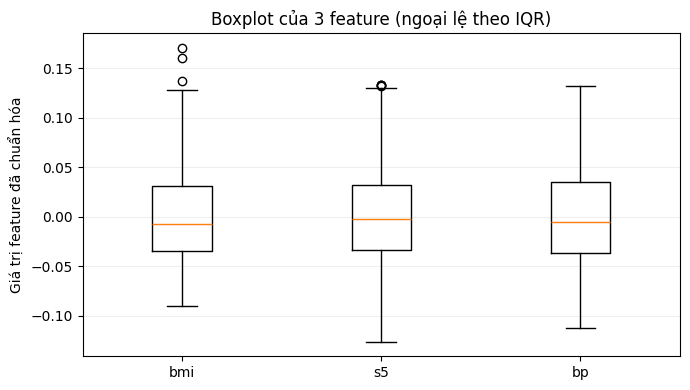

In [ ]:
outlier_rows = []
for col in features_3:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Ngưỡng dưới": lower,
        "Ngưỡng trên": upper,
        "Số ngoại lệ": int(mask.sum()),
        "Tỷ lệ ngoại lệ (%)": mask.mean() * 100,
    })
outlier_df = pd.DataFrame(outlier_rows).round(4)
display(outlier_df)

plt.figure(figsize=(7, 4))
plt.boxplot([df[c] for c in features_3], tick_labels=features_3)
plt.title("Boxplot của 3 feature (ngoại lệ theo IQR)")
plt.ylabel("Giá trị feature đã chuẩn hóa")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

**Nhận xét về outlier:** các điểm nằm ngoài hai ngưỡng `Q1 − 1.5×IQR` và `Q3 + 1.5×IQR` được đánh dấu là ngoại lệ thống kê. Không tự động xóa các điểm này vì chúng có thể là quan sát hợp lệ; cần xem xét kiến thức chuyên môn trước khi loại bỏ.

## 1.4. Tương quan của 3 feature với target

Hệ số tương quan Pearson giữa 3 feature và target:


,Pearson correlation
bmi,0.5865
s5,0.5659
bp,0.4415


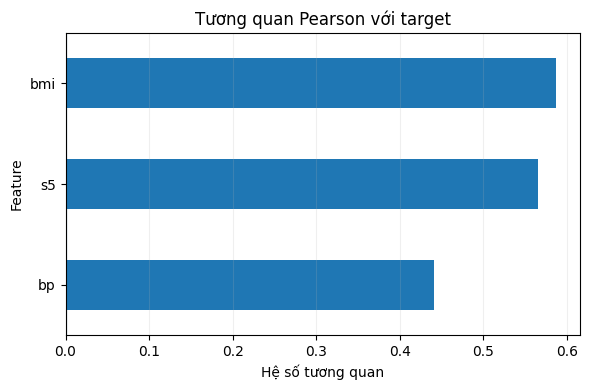

In [ ]:
corr_3 = df[features_3 + ["target"]].corr(numeric_only=True)
target_corr_3 = corr_3["target"].drop("target").sort_values(key=np.abs, ascending=False)
print("Hệ số tương quan Pearson giữa 3 feature và target:")
display(target_corr_3.rename("Pearson correlation").to_frame().round(4))

plt.figure(figsize=(6, 4))
target_corr_3.sort_values().plot(kind="barh")
plt.axvline(0, linewidth=0.8)
plt.title("Tương quan Pearson với target")
plt.xlabel("Hệ số tương quan")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Nhận xét tương quan tự động

In [ ]:
for col, r in target_corr_3.items():
    strength = "mạnh" if abs(r) >= 0.7 else "trung bình" if abs(r) >= 0.4 else "yếu"
    direction = "dương" if r > 0 else "âm" if r < 0 else "gần bằng 0"
    print(f"- {col}: tương quan tuyến tính {direction}, mức độ {strength} (r = {r:.3f}).")
print("Tương quan không chứng minh quan hệ nhân quả và Pearson chủ yếu đo quan hệ tuyến tính.")

## 1.5. Scatter plot của từng feature với target

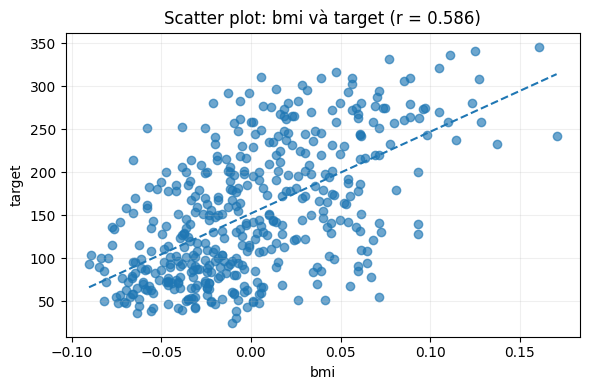

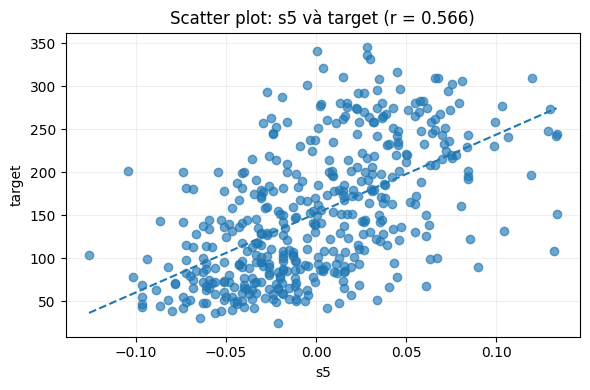

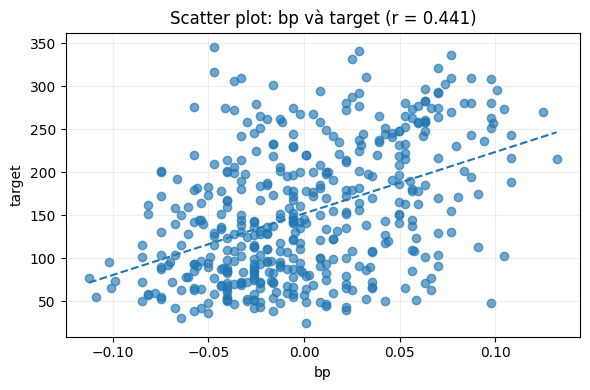

In [ ]:
for col in features_3:
    r = df[[col, "target"]].corr().iloc[0, 1]
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.65)
    # Đường xu hướng tuyến tính để dễ quan sát chiều liên hệ
    slope, intercept = np.polyfit(df[col], df["target"], 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    plt.plot(x_line, slope * x_line + intercept, linestyle="--")
    plt.title(f"Scatter plot: {col} và target (r = {r:.3f})")
    plt.xlabel(col)
    plt.ylabel("target")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

**Nhận xét Bài 1:** dựa vào histogram để mô tả phân phối; bảng IQR/boxplot để nhận xét ngoại lệ; hệ số Pearson để nhận xét chiều và mức độ tương quan; scatter plot để quan sát xu hướng, độ phân tán và các điểm xa xu hướng. Khi chạy notebook, các hệ số và số ngoại lệ sẽ được tính trực tiếp từ dữ liệu.

# BÀI 2. SO SÁNH CÁC NHÓM FEATURE

Huấn luyện **Linear Regression** theo đúng bốn trường hợp trong đề:

1. `bmi`
2. `bmi + bp`
3. Top 5 feature có trị tuyệt đối tương quan với `target` cao nhất
4. Toàn bộ 10 feature

Dùng cùng một cách chia train/test (`test_size=0.2`, `random_state=42`) và đánh giá bằng **MAE, RMSE, R²** để so sánh công bằng. MAE/RMSE càng thấp càng tốt; R² càng cao càng tốt.

## 2.1. Chia dữ liệu và xác định Top 5 feature

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Xếp hạng feature theo trị tuyệt đối tương quan Pearson với target.
# Đây là cách chọn feature đơn giản, phù hợp mục tiêu thực hành trong đề.
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top5_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()

print("Top 5 feature theo |Pearson correlation|:")
display(abs_corr.loc[top5_features].rename("|correlation|").to_frame().round(4))
print("Thứ tự Top 5:", top5_features)

Top 5 feature theo |Pearson correlation|:


,|correlation|
bmi,0.5865
s5,0.5659
bp,0.4415
s4,0.4305
s3,0.3948


Thứ tự Top 5: ['bmi', 's5', 'bp', 's4', 's3']


## 2.2. Huấn luyện và đánh giá 4 mô hình Linear Regression

In [ ]:
feature_groups = {
    "1 feature: bmi": ["bmi"],
    "2 features: bmi + bp": ["bmi", "bp"],
    "Top 5 features": top5_features,
    "All 10 features": list(X.columns),
}

results_bai2 = []
predictions_bai2 = {}
models_bai2 = {}

for model_name, cols in feature_groups.items():
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    models_bai2[model_name] = model
    predictions_bai2[model_name] = pred
    results_bai2.append({
        "Nhóm feature": model_name,
        "Số feature": len(cols),
        "Feature sử dụng": ", ".join(cols),
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
    })

results_bai2_df = pd.DataFrame(results_bai2).sort_values("RMSE").reset_index(drop=True)
display(results_bai2_df.round(4))

,Nhóm feature,Số feature,Feature sử dụng,MAE,RMSE,R²
0,All 10 features,10,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6",42.7941,53.8534,0.4526
1,Top 5 features,5,"bmi, s5, bp, s4, s3",43.9283,54.1893,0.4458
2,2 features: bmi + bp,2,"bmi, bp",50.0441,61.1597,0.2940
3,1 feature: bmi,1,bmi,52.2600,63.7325,0.2334


## 2.3. Biểu đồ so sánh MAE, RMSE và R²

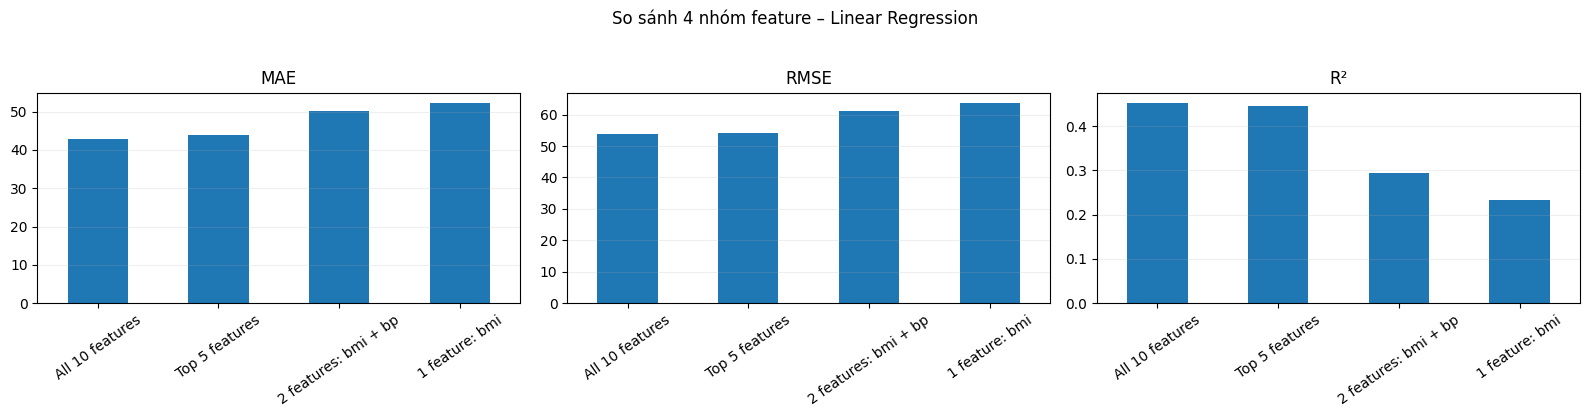

Nhóm có RMSE thấp nhất: All 10 features (RMSE = 53.853).
Nhóm có R² cao nhất: All 10 features (R² = 0.453).
Nhận xét: thêm feature không đảm bảo mô hình luôn tốt hơn; cần dựa vào kết quả trên tập test.


In [ ]:
plot_df = results_bai2_df.set_index("Nhóm feature")[["MAE", "RMSE", "R²"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    plot_df[metric].plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.2)
plt.suptitle("So sánh 4 nhóm feature – Linear Regression", y=1.03)
plt.tight_layout()
plt.show()

best_rmse_row = results_bai2_df.loc[results_bai2_df["RMSE"].idxmin()]
best_r2_row = results_bai2_df.loc[results_bai2_df["R²"].idxmax()]
print(f"Nhóm có RMSE thấp nhất: {best_rmse_row['Nhóm feature']} (RMSE = {best_rmse_row['RMSE']:.3f}).")
print(f"Nhóm có R² cao nhất: {best_r2_row['Nhóm feature']} (R² = {best_r2_row['R²']:.3f}).")
print("Nhận xét: thêm feature không đảm bảo mô hình luôn tốt hơn; cần dựa vào kết quả trên tập test.")

# BÀI 3. SO SÁNH CÁC THUẬT TOÁN HỒI QUY

Sử dụng toàn bộ 10 feature và cùng tập train/test để so sánh:

- Linear Regression
- Ridge Regression
- Decision Tree Regression
- Support Vector Regression (SVR)
- Gradient Boosting Regression

Các mô hình nhạy với thang đo (`Linear Regression`, `Ridge`, `SVR`) được đặt trong pipeline với `StandardScaler`. Dữ liệu đầu vào của Diabetes đã được chuẩn hóa sẵn, nhưng pipeline vẫn giúp quy trình rõ ràng. Cây quyết định và Gradient Boosting không cần chuẩn hóa feature.

## 3.1. Khởi tạo, huấn luyện và đánh giá các thuật toán

In [ ]:
models_bai3 = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42, max_depth=4),
    "Support Vector Regression (SVR)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=100, epsilon=0.1)),
    "Gradient Boosting Regression": GradientBoostingRegressor(
        random_state=42, n_estimators=100, learning_rate=0.05, max_depth=2
    ),
}

results_bai3 = []
predictions_bai3 = {}

for name, model in models_bai3.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions_bai3[name] = pred
    results_bai3.append({
        "Thuật toán": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
    })

results_bai3_df = pd.DataFrame(results_bai3).sort_values("RMSE").reset_index(drop=True)
display(results_bai3_df.round(4))

,Thuật toán,MAE,RMSE,R²
0,Support Vector Regression (SVR),39.4187,51.0641,0.5078
1,Gradient Boosting Regression,42.5461,52.3725,0.4823
2,Ridge Regression,42.8120,53.7775,0.4541
3,Linear Regression,42.7941,53.8534,0.4526
4,Decision Tree Regression,47.0454,59.7408,0.3264


## 3.2. Biểu đồ so sánh các thuật toán

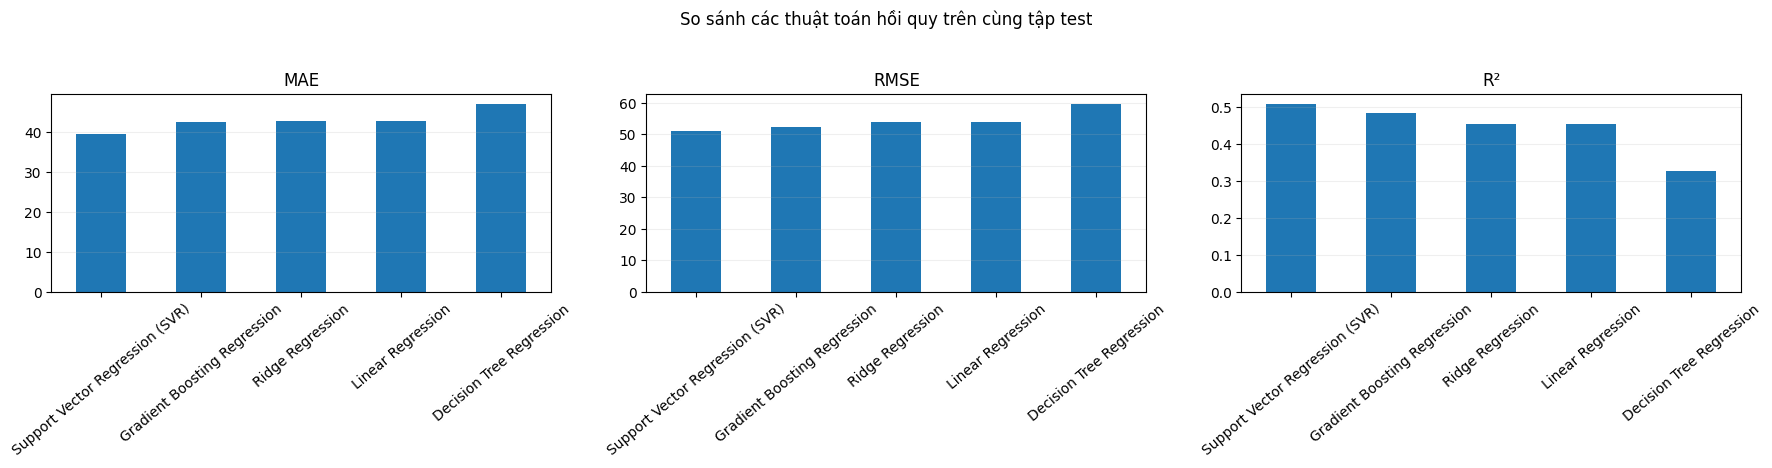

Thuật toán có RMSE thấp nhất: Support Vector Regression (SVR) (RMSE = 51.064).
Thuật toán có MAE thấp nhất: Support Vector Regression (SVR) (MAE = 39.419).
Thuật toán có R² cao nhất: Support Vector Regression (SVR) (R² = 0.508).
Kết quả phụ thuộc cách chia dữ liệu và tham số mô hình; đây là so sánh thực nghiệm, không phải kết luận rằng một thuật toán luôn tốt nhất.


In [ ]:
metrics_df = results_bai3_df.set_index("Thuật toán")[["MAE", "RMSE", "R²"]]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    metrics_df[metric].plot(kind="bar", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=40)
    ax.grid(axis="y", alpha=0.2)
plt.suptitle("So sánh các thuật toán hồi quy trên cùng tập test", y=1.03)
plt.tight_layout()
plt.show()

best_rmse = results_bai3_df.loc[results_bai3_df["RMSE"].idxmin()]
best_mae = results_bai3_df.loc[results_bai3_df["MAE"].idxmin()]
best_r2 = results_bai3_df.loc[results_bai3_df["R²"].idxmax()]
print(f"Thuật toán có RMSE thấp nhất: {best_rmse['Thuật toán']} (RMSE = {best_rmse['RMSE']:.3f}).")
print(f"Thuật toán có MAE thấp nhất: {best_mae['Thuật toán']} (MAE = {best_mae['MAE']:.3f}).")
print(f"Thuật toán có R² cao nhất: {best_r2['Thuật toán']} (R² = {best_r2['R²']:.3f}).")
print("Kết quả phụ thuộc cách chia dữ liệu và tham số mô hình; đây là so sánh thực nghiệm, không phải kết luận rằng một thuật toán luôn tốt nhất.")

## 3.3. So sánh giá trị thực tế và dự đoán của mô hình tốt nhất theo RMSE

Mô hình được hiển thị: Support Vector Regression (SVR)


,Giá trị thực tế,Giá trị dự đoán,Sai số (thực tế - dự đoán)
0,219.0,122.591,96.409
1,70.0,183.424,-113.424
2,202.0,177.939,24.061
3,230.0,220.683,9.317
4,111.0,109.383,1.617
5,84.0,117.330,-33.330
6,242.0,273.341,-31.341
7,272.0,201.325,70.675
8,94.0,115.857,-21.857
9,96.0,111.268,-15.268


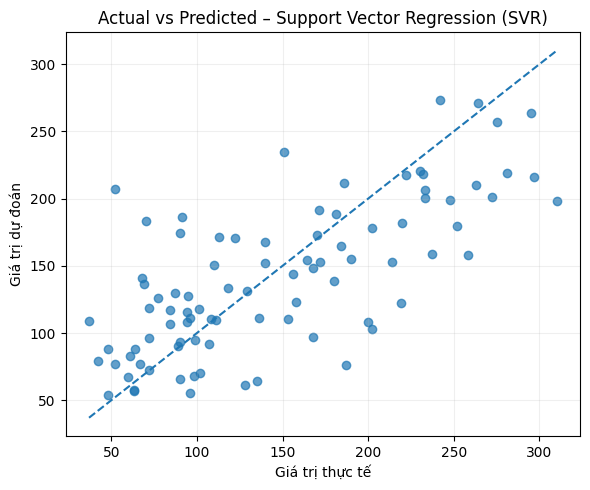

In [ ]:
best_model_name = best_rmse["Thuật toán"]
best_predictions = predictions_bai3[best_model_name]

actual_pred_df = pd.DataFrame({
    "Giá trị thực tế": y_test.to_numpy(),
    "Giá trị dự đoán": best_predictions,
    "Sai số (thực tế - dự đoán)": y_test.to_numpy() - best_predictions,
})
print("Mô hình được hiển thị:", best_model_name)
display(actual_pred_df.head(10).round(3))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, best_predictions, alpha=0.7)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title(f"Actual vs Predicted – {best_model_name}")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# KẾT LUẬN CHUNG

Notebook đã thực hiện đủ các yêu cầu trong ảnh:

- **Bài 1:** phân tích phân phối, ngoại lệ IQR, tương quan với `target` và scatter plot cho 3 feature `bmi`, `s5`, `bp`.
- **Bài 2:** huấn luyện Linear Regression với `bmi`; `bmi + bp`; Top 5 feature theo tương quan; toàn bộ 10 feature. So sánh MAE, RMSE, R².
- **Bài 3:** so sánh Linear Regression, Ridge Regression, Decision Tree Regression, SVR và Gradient Boosting Regression trên cùng cách chia train/test.

**Quy tắc nhận xét:** MAE và RMSE càng nhỏ thì sai số dự đoán càng thấp; R² càng lớn thì mô hình giải thích biến thiên của `target` tốt hơn trên tập đánh giá. Khi viết báo cáo, hãy dùng bảng và các dòng nhận xét được in ra sau khi chạy để nêu mô hình tốt nhất theo từng chỉ số.